In [18]:
import yfinance as yf
import pandas as pd

ticker = "AAPL"

print(f"Downloading data for {ticker}...")

data = yf.download(
    ticker,
    start="2020-01-01"
)

print("\nFirst 5 Rows:\n")
print(data.head())

print("\nShape:")
print(data.shape)

# Save data
data.to_csv(f"data/{ticker}.csv")

print(f"\nSaved to data/{ticker}.csv")

[*********************100%***********************]  1 of 1 completed


First 5 Rows:

Price           Close       High        Low       Open     Volume
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL
Date                                                             
2020-01-02  72.333870  72.394078  71.091176  71.344047  135480400
2020-01-03  71.630653  72.389273  71.406681  71.563221  146322800
2020-01-06  72.201401  72.239935  70.503539  70.754006  118387200
2020-01-07  71.861847  72.466330  71.642689  72.211049  108872000
2020-01-08  73.017853  73.318893  71.565636  71.565636  132079200

Shape:
(1610, 5)

Saved to data/AAPL.csv


In [19]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Load CSV
data = pd.read_csv("data/AAPL.csv", header=[0,1])

print("Original Shape:", data.shape)

close_prices = data[('Close', 'AAPL')]

# Remove NaN values
close_prices = close_prices.dropna()

close_prices = close_prices.values

print("\nFirst 5 Close Prices:")
print(close_prices[:5])

# Reshape
close_prices = close_prices.reshape(-1, 1)

# Scale between 0 and 1
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(close_prices)

print("\nScaled Data Sample:")
print(scaled_data[:5])

# Create sequences
X = []
y = []

sequence_length = 60

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i])

X = np.array(X)
y = np.array(y)
print("NaN Count:", np.isnan(close_prices).sum())
print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Original Shape: (1611, 6)

First 5 Close Prices:
[72.33386993 71.63065338 72.20140076 71.86184692 73.01785278]

Scaled Data Sample:
[[0.07033264]
 [0.06761064]
 [0.06981988]
 [0.06850554]
 [0.07298018]]
NaN Count: 0

X Shape: (1550, 60, 1)
y Shape: (1550, 1)


In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential()

# First LSTM Layer
model.add(
    LSTM(
        units=50,
        return_sequences=True,
        input_shape=(X.shape[1], 1)
    )
)

model.add(Dropout(0.2))

# Second LSTM Layer
model.add(
    LSTM(
        units=50,
        return_sequences=False
    )
)

model.add(Dropout(0.2))

# Output Layer
model.add(Dense(units=1))

# Compile Model
model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()

d:\Stock\stock\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history = model.fit(
    X,
    y,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - loss: 0.0245 - val_loss: 0.0198
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.0031 - val_loss: 0.0024
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.0028 - val_loss: 0.0014
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0025 - val_loss: 0.0018
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0024 - val_loss: 0.0054
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.0027 - val_loss: 0.0039
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0023 - val_loss: 0.0013
Epoch 8/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0021 - val_loss: 0.0016
Epoch 9/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0021 - val_loss: 0.0013
Epoch 10/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0020 - val_loss: 0.0014
Epoch 11/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0018 - val_loss: 0.0011
Epoch 12/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0

In [23]:
model.save("models/AAPL_model.h5")

print("Model Saved Successfully!")

Model Saved Successfully!


In [24]:
predictions = model.predict(X)

print(predictions[:5])

49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
[[0.02742625]
 [0.02741829]
 [0.02787077]
 [0.02797453]
 [0.02798309]]


In [25]:
predictions = scaler.inverse_transform(predictions)
actual = scaler.inverse_transform(y.reshape(-1, 1))

print(predictions[:5])

[[61.249165]
 [61.24711 ]
 [61.364002]
 [61.390812]
 [61.39302 ]]


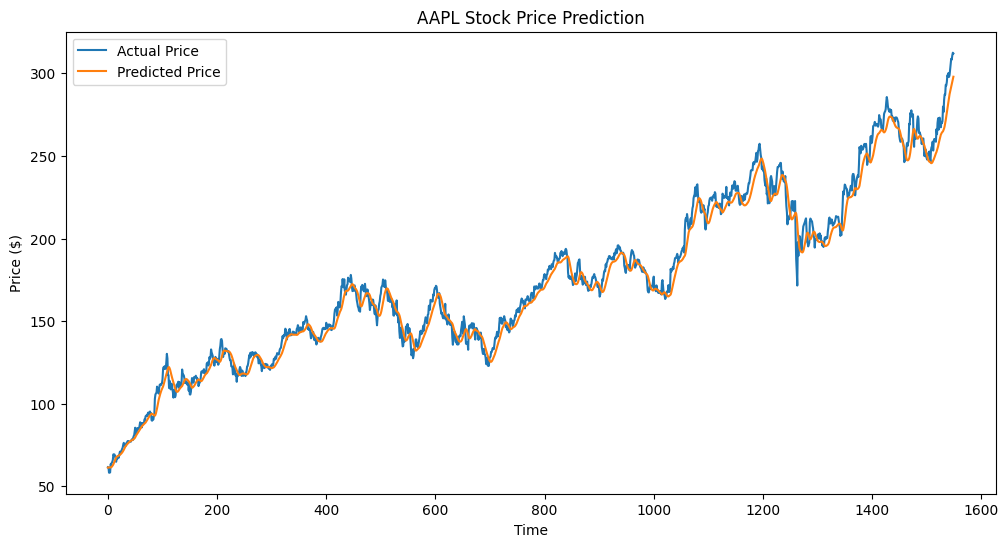

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(actual, label="Actual Price")
plt.plot(predictions, label="Predicted Price")

plt.title("AAPL Stock Price Prediction")
plt.xlabel("Time")
plt.ylabel("Price ($)")
plt.legend()

plt.show()

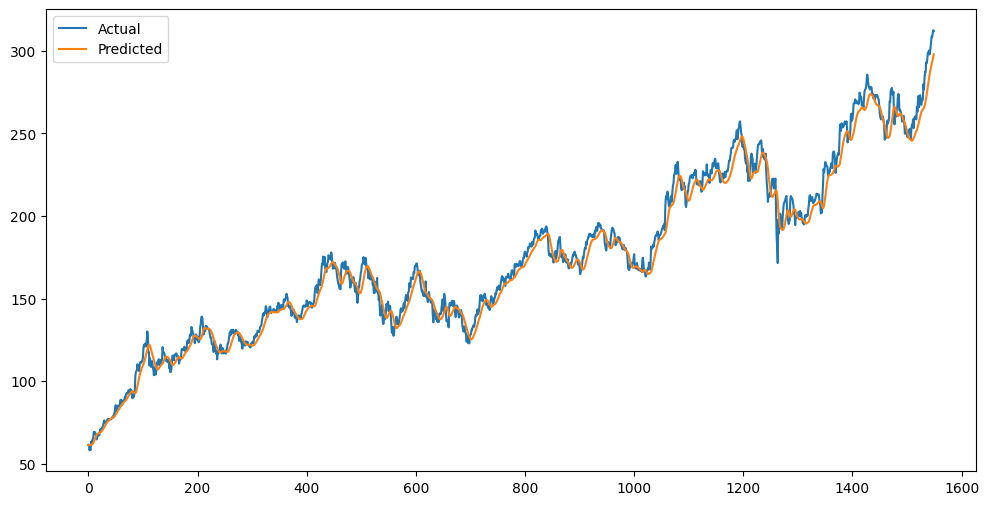

In [27]:
plt.figure(figsize=(12,6))

plt.plot(actual, label="Actual")
plt.plot(predictions, label="Predicted")

plt.legend()

plt.savefig("plots/AAPL_prediction_plot.png")
plt.show()

In [28]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(
    mean_squared_error(actual, predictions)
)

print("RMSE:", rmse)

RMSE: 6.868497201172172


In [29]:
results = pd.DataFrame({
    "Actual": actual.flatten(),
    "Predicted": predictions.flatten()
})

results.to_csv(
    "data/AAPL_predictions.csv",
    index=False
)

results.head()

,Actual,Predicted
0,61.512028,61.249165
1,61.386497,61.247108
2,58.156521,61.364002
3,59.126953,61.390812
4,58.277222,61.393021


In [30]:
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    "data/training_history.csv",
    index=False
)

history_df.head()

,loss,val_loss
0,0.024465,0.019844
1,0.003089,0.002446
2,0.002807,0.001434
3,0.002507,0.001790
4,0.002413,0.005391


In [31]:
from tensorflow.keras.models import load_model

saved_model = load_model(
    "models/AAPL_model.h5"
)

print("Model Loaded!")

Model Loaded!


In [32]:
def predict_next_day(model, data, scaler):
    
    last_60_days = data[-60:]
    
    last_60_days = scaler.transform(
        last_60_days.reshape(-1, 1)
    )
    
    X_test = np.array([last_60_days])
    
    prediction = model.predict(
        X_test,
        verbose=0
    )
    
    prediction = scaler.inverse_transform(
        prediction
    )
    
    return prediction[0][0]

In [35]:
next_price = predict_next_day(
    saved_model,
    close_prices,
    scaler
)

print(
    f"Predicted Next Day Price: ${next_price:.2f}"
)
print("Last Date:", data.index[-1])

Predicted Next Day Price: $299.45
Last Date: 1610


In [37]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(actual, predictions)

print("MAE:", mae)

from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(
    actual,
    predictions
)

print("MAPE:", mape * 100, "%")

from sklearn.metrics import r2_score

r2 = r2_score(actual, predictions)

print("R² Score:", r2)

lower = next_price - rmse
upper = next_price + rmse

print(
    f"Expected Range: ${lower:.2f} - ${upper:.2f}"
)

MAE: 5.3005498701526275
MAPE: 3.007925956425589 %
R² Score: 0.9823373665155009
Expected Range: $292.58 - $306.31


[*********************100%***********************]  1 of 1 completed


Data Shape: (2343, 5)
Close Price Shape: (2343, 1)
X Shape: (2283, 60, 1)
y Shape: (2283, 1)



d:\Stock\stock\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - loss: 0.0223 - val_loss: 0.0015
Epoch 2/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0030 - val_loss: 0.0038
Epoch 3/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - loss: 0.0026 - val_loss: 0.0015
Epoch 4/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - loss: 0.0025 - val_loss: 0.0012
Epoch 5/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - loss: 0.0024 - val_loss: 0.0013
Epoch 6/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 0.0020 - val_loss: 0.0013
Epoch 7/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - loss: 0.0020 - val_loss: 0.0016
Epoch 8/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - loss: 0.0020 - val_loss: 0.0013
Epoch 9/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 0.0020 - val_loss: 0.0011
Epoch 10/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - loss: 0.0020 - val_loss: 0.0011
Epoch 11/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - loss: 0.0020 - val_loss: 0.0016
Epoch 12/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 0.0


Model Saved!
72/72 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step

MODEL PERFORMANCE
RMSE : 2711.12
MAE  : 1871.19
MAPE : 4.18%
R²   : 0.9924

NEXT DAY PREDICTION
Predicted BTC Price: $74,511.27
Expected Range: $71,800.15 - $77,222.40


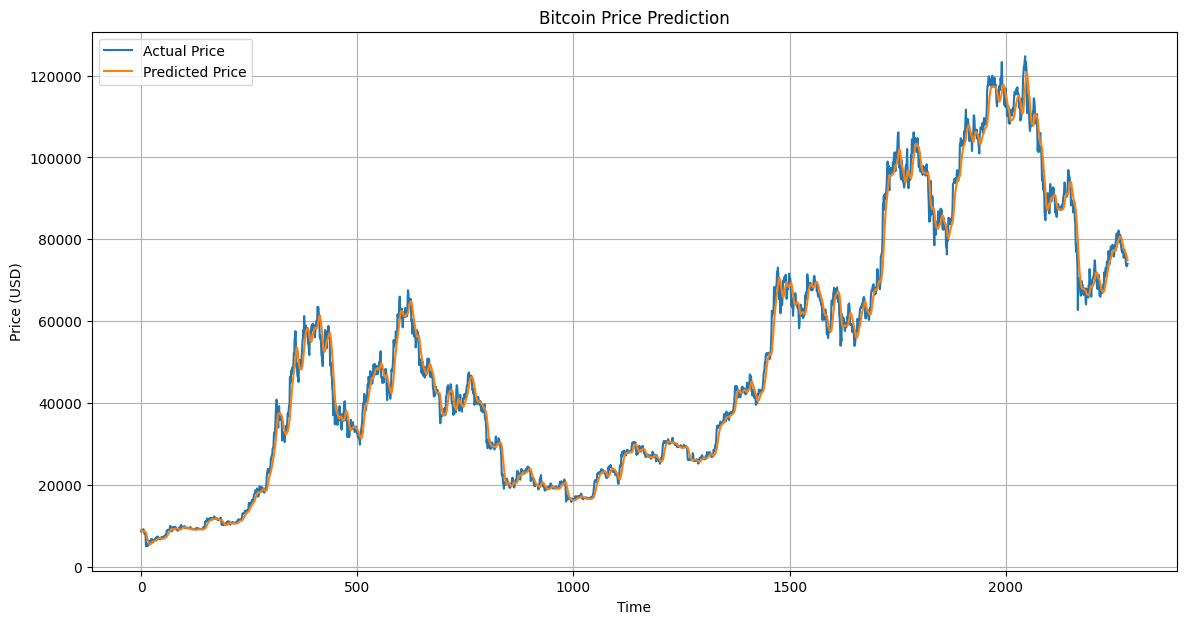

In [39]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout


# =====================================
# DOWNLOAD BITCOIN DATA
# =====================================

ticker = "BTC-USD"

print(f"Downloading data for {ticker}...")

data = yf.download(
    ticker,
    start="2020-01-01"
)
print("\nData Shape:", data.shape)

# =====================================
# EXTRACT CLOSE PRICE
# =====================================

close_prices = data["Close"].dropna().values

close_prices = close_prices.reshape(-1, 1)

print("Close Price Shape:", close_prices.shape)

# =====================================
# SCALE DATA
# =====================================

scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(close_prices)

# =====================================
# CREATE SEQUENCES
# =====================================

X = []
y = []

sequence_length = 60

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i])

X = np.array(X)
y = np.array(y)

print("X Shape:", X.shape)
print("y Shape:", y.shape)

# =====================================
# BUILD LSTM MODEL
# =====================================

model = Sequential()

model.add(
    LSTM(
        units=50,
        return_sequences=True,
        input_shape=(60, 1)
    )
)

model.add(Dropout(0.2))

model.add(
    LSTM(
        units=50,
        return_sequences=False
    )
)

model.add(Dropout(0.2))

model.add(Dense(1))

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

# =====================================
# TRAIN MODEL
# =====================================

history = model.fit(
    X,
    y,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# =====================================
# SAVE MODEL
# =====================================

model.save("models/BTC-USD_model.h5")

print("\nModel Saved!")

# =====================================
# PREDICTIONS
# =====================================

predictions = model.predict(X)

predictions = scaler.inverse_transform(predictions)

actual = scaler.inverse_transform(y)

# =====================================
# METRICS
# =====================================

rmse = np.sqrt(
    mean_squared_error(actual, predictions)
)

mae = mean_absolute_error(
    actual,
    predictions
)

mape = mean_absolute_percentage_error(
    actual,
    predictions
) * 100

r2 = r2_score(
    actual,
    predictions
)

print("\n==============================")
print("MODEL PERFORMANCE")
print("==============================")

print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.4f}")

# =====================================
# NEXT DAY PREDICTION
# =====================================

last_60 = close_prices[-60:]

last_60_scaled = scaler.transform(
    last_60
)

X_future = np.array(
    [last_60_scaled]
)

next_price = model.predict(
    X_future,
    verbose=0
)

next_price = scaler.inverse_transform(
    next_price
)[0][0]

print("\n==============================")
print("NEXT DAY PREDICTION")
print("==============================")

print(
    f"Predicted BTC Price: ${next_price:,.2f}"
)

lower = next_price - rmse
upper = next_price + rmse

print(
    f"Expected Range: ${lower:,.2f} - ${upper:,.2f}"
)

# =====================================
# SAVE PREDICTIONS
# =====================================

results = pd.DataFrame({
    "Actual": actual.flatten(),
    "Predicted": predictions.flatten()
})

results.to_csv(
    "data/BTC_predictions.csv",
    index=False
)

# =====================================
# PLOT RESULTS
# =====================================

plt.figure(figsize=(14, 7))

plt.plot(
    actual,
    label="Actual Price"
)

plt.plot(
    predictions,
    label="Predicted Price"
)

plt.title(
    "Bitcoin Price Prediction"
)

plt.xlabel("Time")

plt.ylabel("Price (USD)")

plt.legend()

plt.grid(True)

plt.savefig(
    "plots/BTC_prediction_plot.png"
)

plt.show()